# 4. Classify raster pixels from labelled points

Learn directly from band values at sample points, predict a class raster in a
separate area, and save the georeferenced result.

This notebook runs independently with the bundled Chesapeake imagery and
reference maps. No data download is needed. From a repository checkout, install
`python -m pip install -e ".[notebooks]"`, then launch `jupyter lab`.
See the [sample data guide](https://obia.sefa.ai/examples/) for source attribution
and data terms.

Run cells from top to bottom. Outputs are saved in
`example_outputs/04_pixel_classification/`; rerunning replaces those files.
Band selections use zero-based numeric indices.

[Download this notebook](04_pixel_classification.ipynb)

In [1]:
from pathlib import Path
import json

import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
import numpy as np
import pandas as pd
import rasterio
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from obia.classification import classify_pixels, sample_pixels
from obia.datasets import chesapeake_sample
from obia.handlers.geotif import open_geotiff

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11})
output_dir = Path("example_outputs") / "04_pixel_classification"
output_dir.mkdir(parents=True, exist_ok=True)
bands = [0, 1, 2, 3]

## Load imagery and point labels

The training and test crops come from separate upstream tiles. Both contain
four-band imagery and an aligned reference map at 1 m resolution.

For this example, take a reference-map sample every 8 pixels. These labels come
from an existing map; they are not independent field observations. For your own
data, load a GeoTIFF with `open_geotiff()` and labelled points with
`gpd.read_file()`. Points need a CRS and a `class` column.

In [2]:
def load_area(split):
    sample = chesapeake_sample(split)
    image = open_geotiff(sample["image"])
    image.rasterio_obj.close()
    with rasterio.open(sample["reference"]) as src:
        reference = src.read(1)
    rows, cols = np.mgrid[4:reference.shape[0]:8, 4:reference.shape[1]:8]
    rows, cols = rows.ravel(), cols.ravel()
    included = np.isin(reference[rows, cols], list(sample["class_names"]))
    rows, cols = rows[included], cols[included]
    xs, ys = rasterio.transform.xy(image.transform, rows, cols)
    points = gpd.GeoDataFrame(
        {"class": [sample["class_names"][int(v)] for v in reference[rows, cols]]},
        geometry=gpd.points_from_xy(xs, ys), crs=image.crs,
    )
    return image, reference, points, sample["class_names"]

image, reference, points, class_names = load_area("train")
print(f"Training raster: {image.img_data.shape}; CRS: {image.crs}")
print(f"Reference-map points: {len(points)}")
display(points["class"].value_counts().rename("sample_points").to_frame())

Training raster: (1024, 1024, 4); CRS: EPSG:26918
Reference-map points: 16384


,sample_points
class,
tree canopy / forest,8284
low vegetation / field,3748
impervious (other),2287
impervious (road),765
barren land,721
water,579


## Inspect the sampled band values

`sample_pixels()` reads the pixel containing each point. The resulting table has
band columns such as `b0` and `b3`, a `feature_class` target, and raster row and
column positions. Its geometries are pixel centres. Point attributes are retained,
but only the selected band values are used as predictors.

Outside points and invalid pixels raise an error by default. Source masks and
nonfinite values in selected bands are respected. Repeated points in the same
pixel count once; contradictory labels must be resolved.

In [3]:
samples = sample_pixels(image, points, bands=bands)
display(samples[["pixel_row", "pixel_col", "b0", "b1", "b2", "b3", "feature_class"]].head())
print(samples.attrs["obia_sampling"])

,pixel_row,pixel_col,b0,b1,b2,b3,feature_class
0,4,4,62.0,67.0,94.0,130.0,tree canopy / forest
1,4,12,82.0,96.0,98.0,164.0,tree canopy / forest
2,4,20,67.0,74.0,92.0,128.0,tree canopy / forest
3,4,28,76.0,84.0,92.0,132.0,tree canopy / forest
4,4,36,70.0,79.0,92.0,144.0,tree canopy / forest


{'bands': (0, 1, 2, 3), 'label_column': 'class', 'input_points': 16384, 'invalid_points': 0, 'duplicate_points': 0, 'sampled_pixels': 16384}


## Fit the classifier

Fit a random forest on all sampled training pixels with `test_size=None`.
The separate test area is reserved for evaluation. `method` accepts the same
classifier names and pipelines as the other classification functions; for example,
use `method="xgboost"` with its constructor parameters.

Prediction runs in batches of at most 32,768 pixels. The loaded image and output
rasters remain in memory. The class map uses positive integer codes and reserves
zero for NoData. `class_mapping` records the original label for each code.

To create a holdout within the training area, build a spatial or grouped split
from `samples` and pass it as `split`. The
[pixel classification guide](https://obia.sefa.ai/usage/pixel-classification/)
shows that workflow.

In [4]:
result = classify_pixels(
    image, points, bands=bands, method="rf",
    n_estimators=60, random_state=42, n_jobs=1,
    test_size=None, batch_size=32768,
)
display(pd.Series(result.class_mapping, name="class_label").rename_axis("raster_code").to_frame())
print(f"Classified raster: {result.classified.shape}; {result.classified.dtype}")
print(f"Valid predicted pixels: {result.valid_mask.sum()}")

,class_label
raster_code,
1,barren land
2,impervious (other)
3,impervious (road)
4,low vegetation / field
5,tree canopy / forest
6,water


Classified raster: (1024, 1024); uint32
Valid predicted pixels: 1048576


## Predict the separate test area

`result.predict()` reuses the fitted model and band positions without refitting.
The new raster must have the same band meanings, order, and value units. Its
size, CRS, and transform may differ.

Use the label mapping to display predictions in the reference map's palette;
raster output codes do not have to equal the original reference codes.

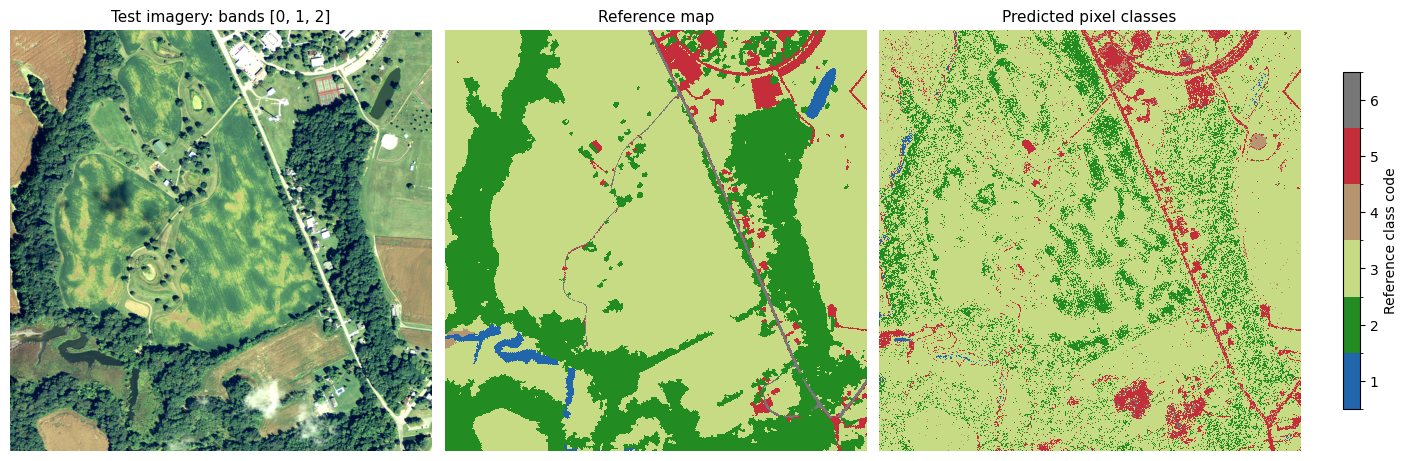

In [5]:
test_image, test_reference, test_points, _ = load_area("test")
prediction = result.predict(test_image, batch_size=32768)

class_cmap = ListedColormap(["#2166ac", "#228b22", "#c6db83", "#b69571", "#c42e3a", "#777777"])
class_cmap.set_bad("#eeeeee")
class_norm = BoundaryNorm(np.arange(0.5, 7.5), class_cmap.N)
name_to_reference = {name: code for code, name in class_names.items()}
lookup = np.zeros(len(prediction.classes) + 1, dtype=np.uint8)
for code, name in prediction.class_mapping.items():
    lookup[code] = name_to_reference[name]
display_codes = np.ma.masked_equal(lookup[prediction.classified], 0)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), layout="constrained")
axes[0].imshow(test_image.to_image([0, 1, 2]))
axes[0].set_title("Test imagery: bands [0, 1, 2]")
axes[1].imshow(test_reference, cmap=class_cmap, norm=class_norm, interpolation="nearest")
axes[1].set_title("Reference map")
plot = axes[2].imshow(display_codes, cmap=class_cmap, norm=class_norm, interpolation="nearest")
axes[2].set_title("Predicted pixel classes")
fig.colorbar(plot, ax=axes[1:], ticks=list(class_names), label="Reference class code", shrink=0.8)
for ax in axes:
    ax.set_axis_off()
plt.show()

## Evaluate agreement at the test points

Sample the test points and read their predictions from the class raster. These
points were not used to fit the model. The report measures agreement with the
reference map at the sampled pixels; it does not establish whole-map or regional
accuracy. Check class support as well as scores, since some classes have few
samples. Reference maps can contain errors or date mismatches.

                        precision    recall  f1-score   support

           barren land       0.00      0.00      0.00        18
    impervious (other)       0.37      0.67      0.48       565
     impervious (road)       0.10      0.03      0.05       161
low vegetation / field       0.68      0.85      0.76     10408
  tree canopy / forest       0.51      0.23      0.32      5020
                 water       0.41      0.08      0.13       212

              accuracy                           0.63     16384
             macro avg       0.35      0.31      0.29     16384
          weighted avg       0.61      0.63      0.60     16384



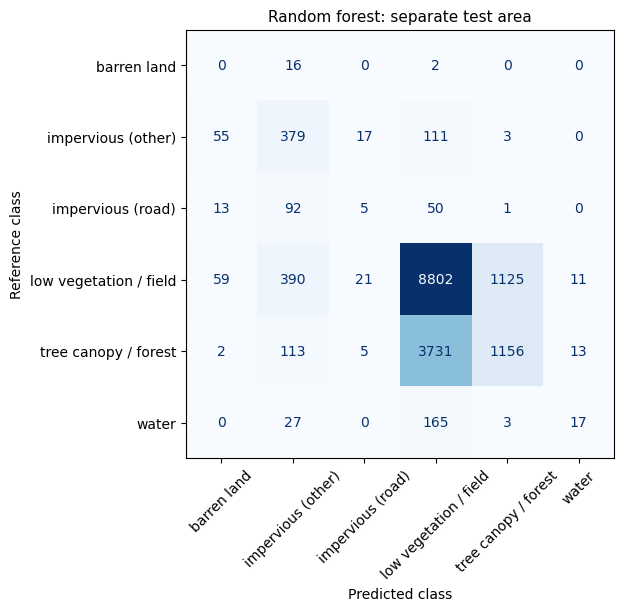

In [6]:
test_samples = sample_pixels(test_image, test_points, bands=result.bands)
pixel_codes = prediction.classified[test_samples.pixel_row, test_samples.pixel_col]
assert (pixel_codes > 0).all()
predicted_labels = prediction.classes[pixel_codes - 1]
print(classification_report(test_samples.feature_class, predicted_labels,
                            labels=prediction.classes, zero_division=0))
cm = confusion_matrix(test_samples.feature_class, predicted_labels, labels=prediction.classes)
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
ConfusionMatrixDisplay(cm, display_labels=prediction.classes).plot(
    ax=ax, colorbar=False, cmap="Blues", xticks_rotation=45,
)
ax.set_title("Random forest: separate test area")
ax.set_xlabel("Predicted class")
ax.set_ylabel("Reference class")
plt.show()

## Save the class map and training samples

The output GeoTIFF preserves the test raster's grid and CRS. Its `class_mapping`
metadata tag maps positive codes to labels; zero is reserved for NoData.
The sampled training table can be inspected in GIS.

`prediction_margin` is the gap between the two largest class probabilities.
It indicates ambiguity, not calibrated accuracy. For a full probability array,
pass `return_probabilities=True` to classification or prediction; this adds one
raster layer per class in memory. Classifiers without probabilities still return
a class map, with missing margins.

In [7]:
output_path = output_dir / "pixel_classes.tif"
prediction.write_geotiff(output_path)
result.samples.to_file(output_dir / "training_pixels.gpkg", driver="GPKG")
with rasterio.open(output_path) as src:
    assert src.crs == test_image.crs and src.transform == test_image.transform
    np.testing.assert_array_equal(src.read(1), prediction.classified)
    saved_mapping = json.loads(src.tags()["class_mapping"])
print(f"Saved raster: {output_path}")
print("Class mapping:", saved_mapping)

Saved raster: example_outputs/04_pixel_classification/pixel_classes.tif
Class mapping: {'1': 'barren land', '2': 'impervious (other)', '3': 'impervious (road)', '4': 'low vegetation / field', '5': 'tree canopy / forest', '6': 'water'}


For your own imagery, choose band indices explicitly and check the sample labels
before fitting. Use training-area validation for model choices and reserve an
independent area for final evaluation. See the
[classifier guide](https://obia.sefa.ai/usage/classification/) for model options and
[training and validation](https://obia.sefa.ai/usage/validation/) for split design.